# ⚛️ ECHO — Entangled Minds: The Quantathon
**Team:** Inam
**Mandatory modules:** 01 · 03 · 05  **Stretch module:** 02 — The Honest Coin

Each module below has its code, its result, and a one-line **"What it proves"**.
Run with **Runtime → Restart and run all**.

## 0 · Setup

In [1]:
!pip install qiskit qiskit-aer pylatexenc --quiet
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram


sim = AerSimulator()
def run(qc, shots=1024):
    """Run a circuit many times and count the outcomes."""
    return sim.run(transpile(qc, sim), shots=shots).result().get_counts()



   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.1/10.1 MB 91.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 14.2/14.2 MB 50.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 137.5/137.5 kB 8.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 48.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.9/54.9 kB 3.0 MB/s eta 0:00:00


---
## Module 01 · The Gatekeeper *(mandatory)*
Gates allowed: H · X · measure.

###  Bronze — a bit that is always 1, and a bit that is 50/50

In [2]:
qc = QuantumCircuit(2, 2)
qc.x(0)          # qubit 0 → always 1
qc.h(1)          # qubit 1 → 50/50
qc.measure([0, 1], [0, 1])
counts = run(qc)
print(counts)    # Qiskit reads right to left: rightmost digit = qubit 0


{'01': 487, '11': 537}


**Result:** only `01` and `11` — the rightmost digit (qubit 0) is always 1, the left digit (qubit 1) is random.
**What it proves:** X deterministically flips 0 → 1, while H creates a superposition that measures 0 or 1 with equal probability.

###  Silver — looks uncertain, but is secretly certain

In [3]:
qc = QuantumCircuit(1, 1)
qc.h(0)
qc.h(0)
qc.measure(0, 0)
print("H then H:", run(qc))           # → always 0

# Comparison: measuring in the middle breaks it
qc = QuantumCircuit(1, 1)
qc.h(0)
qc.measure(0, 0)
qc.h(0)
qc.measure(0, 0)
print("H, measure, H:", run(qc))      # → 50/50

H then H: {'0': 1024}
H, measure, H: {'0': 487, '1': 537}


**Result:** H·H gives `0` every time; measuring between the two H gates gives 50/50.
**What it proves:** the two H gates interfere and cancel, so a state that looks random is actually certain  , unless a measurement causes it to collapse first.

###  Gold — the vault code 101, built from 000

In [4]:
qc = QuantumCircuit(3, 3)
qc.x([0, 2])     # flip qubits 0 and 2
qc.measure([0, 1, 2], [0, 1, 2])
print(run(qc))   # → {'101': 1024}

{'101': 1024}


**Result:** `101` on every shot.
**What it proves:** X on qubits 0 and 2 deterministically produces 101; Qiskit prints qubit 0 as the rightmost digit (e.g. `qc.x(0)` alone gives `001`).

---
## Module 03 · The Two Observers *(mandatory)*
Gates allowed: H · X · CNOT · measure.

###  Bronze — a pair that only ever agrees


{'00': 523, '11': 501}


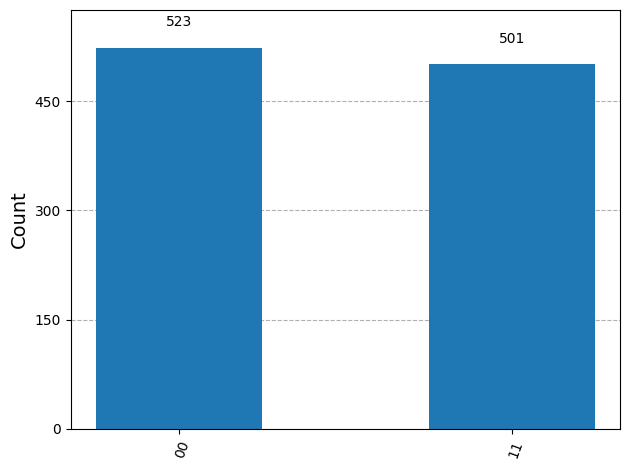

In [5]:
qc = QuantumCircuit(2, 2)
qc.h(0)
qc.cx(0, 1)
qc.measure([0, 1], [0, 1])
counts = run(qc)
print(counts)    # → only '00' and '11'
plot_histogram(counts)

**Result:** only `00` and `11`, never `01` or `10`.
**What it proves:** H then CNOT creates an entangled Bell pair — the two qubits always agree.

###  Silver — a pre-agreed secret also always agrees

In [6]:
qc = QuantumCircuit(2, 2)
qc.h(0)
qc.measure(0, 0)     # coin flipped and looked at → now an ordinary bit
qc.cx(0, 1)          # copy that bit to the other person
qc.measure([0, 1], [0, 1])
print(run(qc))       # → only '00' and '11' too

{'00': 509, '11': 515}


**Result:** also only `00` and `11` — identical to the real pair.
**What it proves:** "always agreeing" alone does not prove a quantum link,it is more like a shared secret key both sides agreed on beforehand. The only difference from Bronze is measuring *before* the CNOT.

###  Gold — an experiment that tells them apart

In [7]:
# Real quantum pair, measured in the +/- basis (H before measuring)
qc = QuantumCircuit(2, 2)
qc.h(0)
qc.cx(0, 1)
qc.h([0, 1])
qc.measure([0, 1], [0, 1])
quantum = run(qc)
print("Quantum pair:", quantum)   # → still only '00' and '11'

# Pre-agreed secret, measured the same way
qc = QuantumCircuit(2, 2)
qc.h(0)
qc.measure(0, 0)
qc.cx(0, 1)
qc.h([0, 1])
qc.measure([0, 1], [0, 1])
secret = run(qc)
print("Secret coin: ", secret)    # → all four outcomes



Quantum pair: {'11': 505, '00': 519}
Secret coin:  {'01': 233, '11': 273, '00': 250, '10': 268}


**Result:** the quantum pair still agrees 100%; the secret-coin pair gives all four outcomes (~50% agreement).
**What it proves:** the entangled pair agrees no matter how you measure, while a pre-agreed secret only agrees in the basis it was fixed in.


---
## Module 05 · The Damaged Message *(mandatory)*
Each bit was sent three times; at most one of each three was flipped.

In [8]:
# the corrupted stream, as given in the organizers' notebook
stream = "100011001001001011100110001011000000001100011011000111000000110000001000000111001010101011111111"

# cut the 96 bits into 32 triples
triples = []
for i in range(0, len(stream), 3):
    triples.append(stream[i:i+3])

def decode(triples):
    # Step 1: majority vote each triple → 1 bit
    OG = []
    for t in triples:
        if t.count("1") >= 2:
            OG.append("1")
        else:
            OG.append("0")
    bits = "".join(OG)
    # Step 2: every 8 bits → 1 letter
    message = ""
    for i in range(0, len(bits), 8):
        message += chr(int(bits[i:i+8], 2))
    return bits, message

###  Bronze — recover the original message

In [9]:
bits, message = decode(triples)
print("Recovered bits:", bits)
print("Message:", message)

Recovered bits: 01000101010000110100100001001111
Message: ECHO


**Result:** the 32 recovered bits decode to the word **ECHO**.
**What it proves:** with at most one flip per triple, majority vote recovers every original bit.

###  Silver — where the trick breaks

In [10]:
broken = list(triples)                # a copy, so the original stays safe
print(broken[0], "→ votes 0 (correct)")
broken[0] = "110"                     # two of the three bits corrupted
print(broken[0], "→ votes 1 (WRONG)")

bits, message = decode(broken)
print("Message now:", message)        # first letter is corrupted

100 → votes 0 (correct)
110 → votes 1 (WRONG)
Message now: ÅCHO


**Result:** changing triple 0 from `100` to `110` makes the vote pick 1, and the first letter turns into a garbage character.
**What it proves:** if 2 of 3 copies flip, the wrong value wins the vote — and it fails silently, because `110` looks like a normal triple.

###  Gold (part 1) — how many flips can it correct vs. notice?

In [11]:
# Original bit = 0, so the sender sent "000"
tests = {
    "0 flips": "000",
    "1 flip ": "100",
    "2 flips": "110",
    "3 flips": "111",
}
for name, received in tests.items():
    vote = "1" if received.count("1") >= 2 else "0"
    noticed = received not in ["000", "111"]   # mixed = damage spotted
    correct = (vote == "0")
    print(f"{name}: {received} → vote {vote} | noticed: {noticed} | fixed right: {correct}")

0 flips: 000 → vote 0 | noticed: False | fixed right: True
1 flip : 100 → vote 0 | noticed: True | fixed right: True
2 flips: 110 → vote 1 | noticed: True | fixed right: False
3 flips: 111 → vote 1 | noticed: False | fixed right: False


**Answer:** only `000` or `111` are ever sent, so damage is noticed only when a triple is mixed.
- **Corrects 1 flip** — the two unflipped bits still win the vote.
- **Notices 2 flips** but fixes them wrongly — the flipped bits are now the majority.
- **Misses 3 flips** — `000` → `111` looks like a valid triple.

###  Gold (part 2) — why can't you protect a qubit by copying it three times?
1. **You can't copy a qubit.** Quantum rules (no-cloning) don't allow it. The closest we can get is CNOT, which links the qubits together instead of copying.
2. **You can't vote without looking.** To vote, you have to measure each copy, and measuring turns the qubit into a plain 0 or 1, so the quantum information is lost.
3. **Qubits have a hidden kind of error.** Besides flipping 0 , 1, a qubit can get a sign flip (+ , −). Measuring 0/1 can't see it, so voting would miss it completely.



In [12]:
# Proof that CNOT does not copy: try to copy "+" and "-"
qc = QuantumCircuit(2, 2)
qc.h(0)              # make +
qc.cx(0, 1)          # try to copy
qc.h([0, 1])         # ask "+ or -?"
qc.measure([0, 1], [0, 1])
print("Copy +:", run(qc), "| a real copy would give 00 only")

qc = QuantumCircuit(2, 2)
qc.x(0)
qc.h(0)              # make -
qc.cx(0, 1)          # try to copy
qc.h([0, 1])         # ask "+ or -?"
qc.measure([0, 1], [0, 1])
print("Copy -:", run(qc), "| a real copy would give 11 only")

Copy +: {'11': 522, '00': 502} | a real copy would give 00 only
Copy -: {'10': 503, '01': 521} | a real copy would give 11 only


**Result:** copying + gives `00`/`11`; copying − gives `01`/`10`.
**What it proves:** CNOT makes an entangled pair, not a copy — no-cloning holds for both + and −.

---
## Module 02 · The Honest Coin *(stretch)*
ECHO was triggered by a "random" quantum seed. Should Zara have trusted it?

###  Bronze — a genuinely fair quantum coin

In [13]:
qc = QuantumCircuit(1, 1)
qc.h(0)
qc.measure(0, 0)
shots = 1000
counts = run(qc, shots=shots)
p1 = counts.get('1', 0) / shots
print(counts, " P(1) =", p1)

{'1': 507, '0': 493}  P(1) = 0.507


**Result:** P(1) ≈ 0.5.
**What it proves:** H gives equal amplitudes to 0 and 1, so the measurement is a genuinely fair coin (apart from small random wobble).

###  Silver — run the recovered seed circuit (unchanged)

In [14]:
# the recovered seed circuit, run as-is
seed = QuantumCircuit(1, 1)
seed.ry(1.159, 0)
seed.measure(0, 0)
seed_counts = run(seed, shots=1024)
p2 = seed_counts.get('1', 0) / shots
print(seed_counts, " P(1) =", p2)


{'1': 301, '0': 723}  P(1) = 0.301


**Result:** about **70% 0 and 30% 1**, not 50/50.
**What it proves:** the seed only *looks* random , but in reality it is not.

### Gold — put a number on the bias, and how many shots you need

In [15]:
# Module 02 · Gold: how biased is the seed?
shots = 1024
p1 = seed_counts.get('1', 0) / shots      # fraction of 1s

wobble = (0.25 / shots) ** 0.5            # how much a FAIR coin naturally wobbles
z = (p1 - 0.5) / wobble                   # how many wobbles away from 50%

print("P(1) =", round(p1, 2))
print("z =", round(z, 1))
print("RIGGED" if abs(z) > 3 else "fair")

bias = abs(p1 - 0.5)
print("Shots needed to be sure:", round(2.25 / bias**2))

P(1) = 0.29
z = -13.2
RIGGED
Shots needed to be sure: 53


**Result:** P(1) ≈ 0.30, bias ≈ −0.20, **z ≈ −13** → rigged.  Only **~57 shots**.
**What it proves:** the trigger was a 70/30 loaded coin, and 1.159 is almost exactly the angle for a clean 70/30 split (1.1593). ECHO firing was not chance; someone chose that angle.

## Summary

| Module | What we got | What it shows |
|---|---|---|
| 01 | X always gives 1, H gives 50/50, H then H gives 0 every time, X on qubits 0 and 2 gives 101 | Some gates are fixed, H makes a mix, and two H's cancel out, so something can look random but actually isn't |
| 03 | The real pair still matches even when we change how we measure, but the secret-coin pair stops matching | The pair really is linked, but each person alone just sees random results, so nothing gets sent |
| 05 | Majority vote gave us **ECHO**, 2 flips break it, and CNOT can't copy a qubit | Copying and voting works for normal bits but not for qubits |
| 02 | H gives a fair 50/50, but the seed gives 70/30, which is way off (z about −13) | The "random" coin that started ECHO was rigged |

**Bottom line:** the detectors only agreed, they never sent anything. And ECHO didn't start by luck, because the coin was loaded.